In [106]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

In [107]:
%cd /Users/michelefilippucci/Data/NCEP2
!ls 

/Users/michelefilippucci/Data/NCEP2
NCEP2_northem_2.5x2.5_zg500_daily_1948-2021.nc
NCEP2_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1948-2021.nc
NCEP2_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1948-2021.nc
dictionaries
download_script.sh
hgt
hgt.1991.nc
index.html
prepare_dataset.ipynb
wget-log


In [108]:
ds_filt = xr.open_dataset('NCEP2_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1948-2021.nc')
ds_unfilt = xr.open_dataset('NCEP2_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1948-2021.nc')


In [109]:
#Greenland coordinates
plon,plat=-35.0,70.0 #Greenland

In [110]:
DAV_filt = ds_filt['DAV_tracked']
DAV_unfilt = ds_unfilt['DAV_tracked']
zg = ds_filt['zg']

In [111]:
times = ds_filt['time']
lons = ds_filt['lon']
lats = ds_filt['lat']

In [112]:
def running_mean(data,window):
    new_data = []
    for i in range(len(data)-window):
        new_data.append(np.sum(data[i:i+window])/window)
    print(len(new_data))
    return new_data

In [113]:
count = 0
count_m = 0
months = ['06','07','08']
DAV_series = DAV_filt.loc[:,plat,plon]
freq_per_year = []
tmp = 0
for t,time in tqdm(enumerate(times)):
    month = str(time.values)[5:7]
    time_diff = t-tmp
    if month in months:
        count_m +=1
        if DAV_series[t] > 0:
            count += 1
    if time_diff == 365:
        tmp = t
        freq_per_year.append(count/count_m)
        count = 0
        count_m = 0

27029it [00:04, 5530.91it/s]


In [114]:
def fit_with_bootstrap(freq_per_year,years,N_it):
    pends = []
    count = 0
    for i in range(N_it):
        tmp = np.random.choice(freq_per_year, size=len(freq_per_year),replace=False)
        coefficients = np.polyfit(years, tmp, 1)
        pend = coefficients[0]
        pends.append(pend)
    coefficients = np.polyfit(years, freq_per_year, 1)
    pend_exp = coefficients[0]
    for pend in pends:
        if abs(pend) > abs(pend_exp):
            count += 1
    p_value = count/N_it
    return pend_exp,p_value

64
0.000754149026930431 0.006


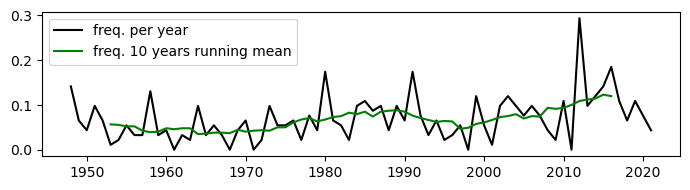

In [117]:
window = 10
freq_per_year_run_avg = running_mean(freq_per_year,window)
years = np.arange(1948,2022,1)
years_run_avg = years[int(window/2):int(-window/2)]


# Fit linear regression model with errors
pend,p_value = fit_with_bootstrap(freq_per_year,years,2000)

print(pend,p_value)

plt.rcParams['figure.figsize'] = [7,2]
plt.plot(years,freq_per_year,color='black',label='freq. per year')
plt.plot(years_run_avg,freq_per_year_run_avg,color='g',label='freq. 10 years running mean')
plt.legend()
plt.tight_layout()
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/frequency_NCEP2',dpi=300)

In [51]:
print(pend,p_value)

0.0007136694384406499 0.0


In [52]:
DAV_bool = DAV_filt
ds = ds_filt
#dimensions of the needed fields.
lonHotSpot = BT.GetIndex(ds_filt,"lon",str(plon))
latHotSpot = BT.GetIndex(ds_filt,"lat",str(plat)) 
dic_for_filtering = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023_DIC.npy',allow_pickle=True) #original
#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(ds["time"].values))):
    for l in np.unique(DAV_bool[t,:,:]):
        if l < 4907: #i need to fix this but couriously it's working
            month = str(dic_for_filtering[l-1]['date'])[5:7]
        if l!=0 and np.all(l==DAV_bool[t:t+1,latHotSpot,lonHotSpot]) and month in months and not l in indexes: #and dic_for_filtering[l-1]['distance_traveled']>1500#DAV_bool[t-1,:,:]:
            indexes.append(l)
            timings.append(t)
print(len(indexes))

100%|████████████████████████████████████████████████████████████████| 30681/30681 [00:32<00:00, 943.83it/s]

149


In [53]:
print(len(dic_for_filtering))

4907


In [54]:
print(np.amax(DAV_bool))

<xarray.DataArray 'DAV_tracked' ()>
array(4910)


In [55]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l-1]['track']
    dic[i]['area'] = dic_for_filtering[l-1]['avg_area']
    dic[i]['date'] = dic_for_filtering[l-1]['date']
    dic[i]['avg_dist_traveled'] = dic_for_filtering[l-1]['avg_dist_traveled']

149it [00:00, 503586.86it/s]


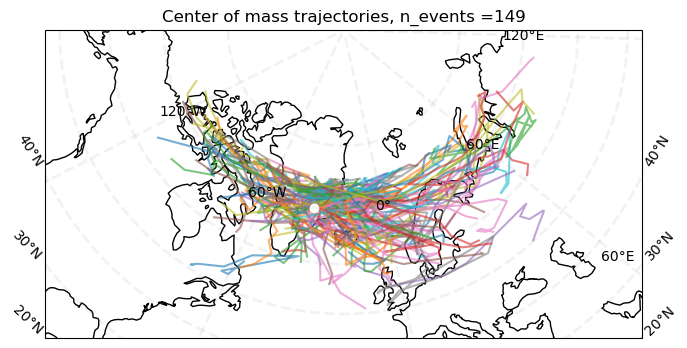

In [56]:
'''
TRAJECTORY PLOT
'''

import matplotlib.ticker as mticker

plt.figure(figsize=(8,4))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories_"+str(plon)+"-"+str(plat)+".png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.LambertConformal(central_longitude=-20)
datacrs = ccrs.PlateCarree()
extent =[-140,+100,45,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=2, color='gray', alpha=0.1, linestyle='--')
#gl.xlocator = mticker.FixedLocator([plon])
#gl.ylocator = mticker.FixedLocator([plat])
#gl.xlabels_top = False
#gl.ylabels_left = False
for i in range(len(xs)):
    cm = plt.plot(ys[i],xs[i],alpha=0.6,transform=datacrs)
#plt.text(30,60, 'n_events='+str(len(xs)), fontsize = 9)
plt.plot(lons[lonHotSpot],lats[latHotSpot],'ow',transform=datacrs)#transorm=datacrs)
plt.title('Center of mass trajectories, n_events =' + str(len(xs)), loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/trajectories.png',dpi=300)


In [57]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
            "month":str(ds["time"].values[timings[i]])[5:7],
            "year":str(ds["time"].values[timings[i]])[0:4],
            "avg_area":np.mean(areas[i]),
            "duration":len(xs[i]),
            "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
            "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
            "displacement_lon":plon-xs[i][0],
            "displacement_lat":plat-ys[i][0]
            }
    feature_dictionaries.append(event)

149it [00:00, 40314.24it/s]


In [58]:
def feature_list(feature_dictionaries,quantity,bin_size_y=10,year_range=(1943,2024)):
    y_array = np.arange(year_range[0]+bin_size_y/2,year_range[1]-bin_size_y/2,1)
    arr = np.zeros(len(y_array))
    arr_err = np.zeros(len(y_array))
    list_err = []
    for j,y in enumerate(y_array):
        count = 0
        for item in feature_dictionaries:
            if int(item["year"]) >= y-bin_size_y/2 and int(item["year"]) < y + bin_size_y/2:
                count += 1
                try:
                    arr[j] += item[quantity]
                    list_err.append(item[quantity])
                except:
                    arr[j] += 1 #the number of events case
        if quantity != "number_of_events":
            arr[j] = arr[j]/count
    if quantity != "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j] = np.std(list_err)
    if quantity == "number_of_events":
        for j,y in enumerate(y_array):
            arr_err[j]=np.std(arr[:])
    return y_array,arr,arr_err

-1365.2277760410814 0.0635
0.08289738430583485 0.0
0.006461006916716846 0.281


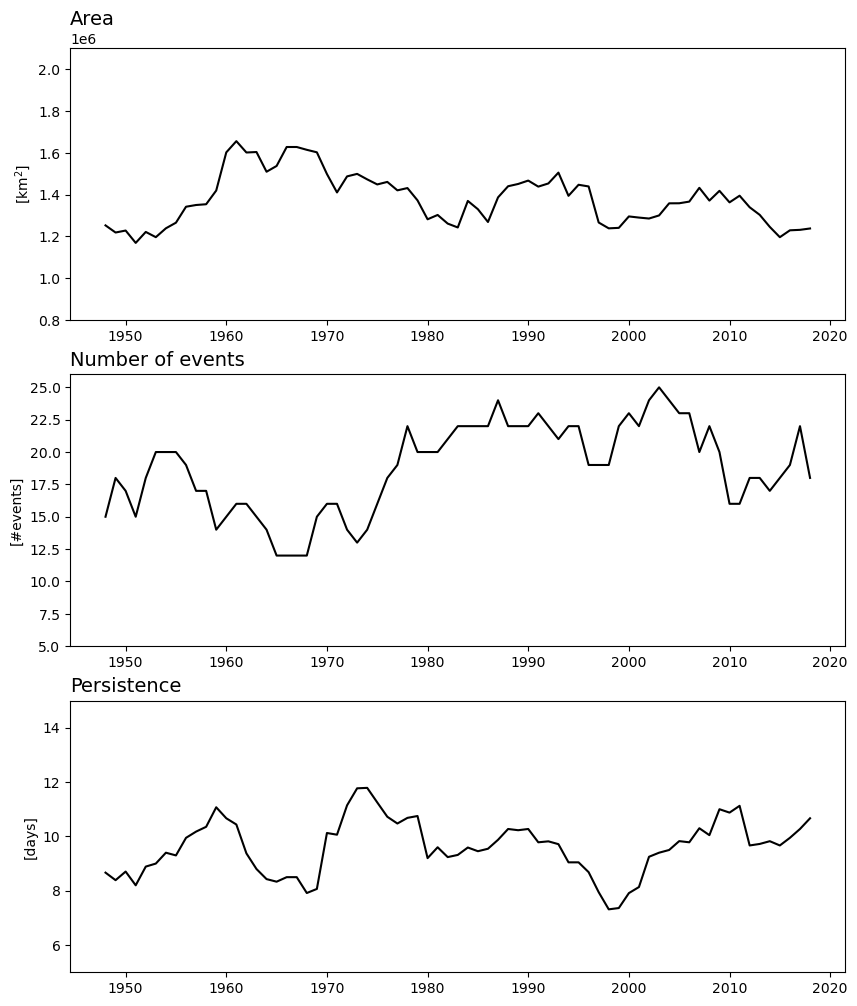

In [79]:
y,area,area_err = feature_list(feature_dictionaries,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)

plt.rcParams['figure.figsize'] = [10,12]
fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events]')
axes[1].set_ylim((5,26))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))


plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics.png',dpi=300)

In [80]:
# LET'S TRY TO SELECT EVENTS COMING FROM THE WEST AND EAST
feature_dictionaries_east = []
feature_dictionaries_west = []
for i,l in tqdm(enumerate(indexes)):
    displacement_lon = plon-xs[i][0]
    if displacement_lon < 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_east.append(event)
    if displacement_lon >= 0:
        event = {"label":l,
                "month":str(ds["time"].values[timings[i]])[5:7],
                "year":str(ds["time"].values[timings[i]])[0:4],
                "avg_area":np.mean(areas[i]),
                "duration":len(xs[i]),
                "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
                "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
                "displacement_lon":plon-xs[i][0],
                "displacement_lat":plat-ys[i][0]
                }
        feature_dictionaries_west.append(event)

149it [00:00, 34221.40it/s]


-3242.4078124814464 0.003
0.06029510395707561 0.0005
-0.004263350434124746 0.572
85


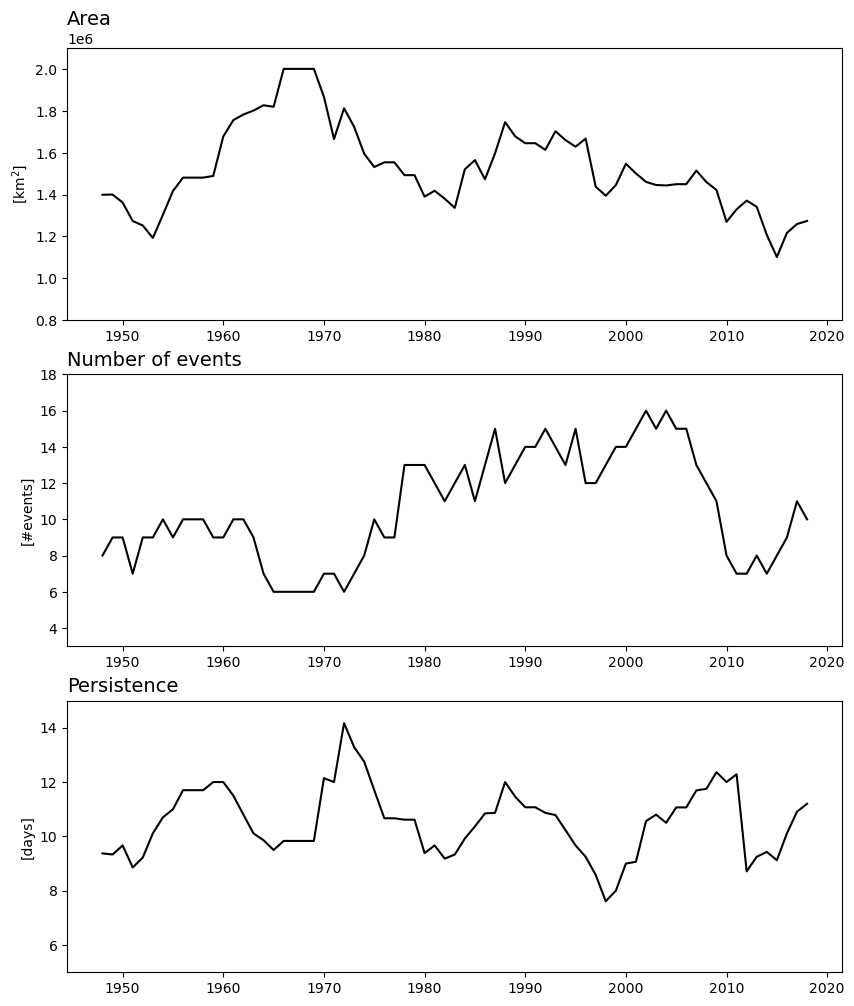

In [88]:
#EAST

y,area,area_err = feature_list(feature_dictionaries_east,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_east,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_east,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)
print(len(feature_dictionaries_east))

plt.rcParams['figure.figsize'] = [10,12]
fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events]')
axes[1].set_ylim((3,18))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_east.png',dpi=300)


-529.3066789357581 0.5295
0.022602280348759236 0.0115
0.010743727637590824 0.137
64


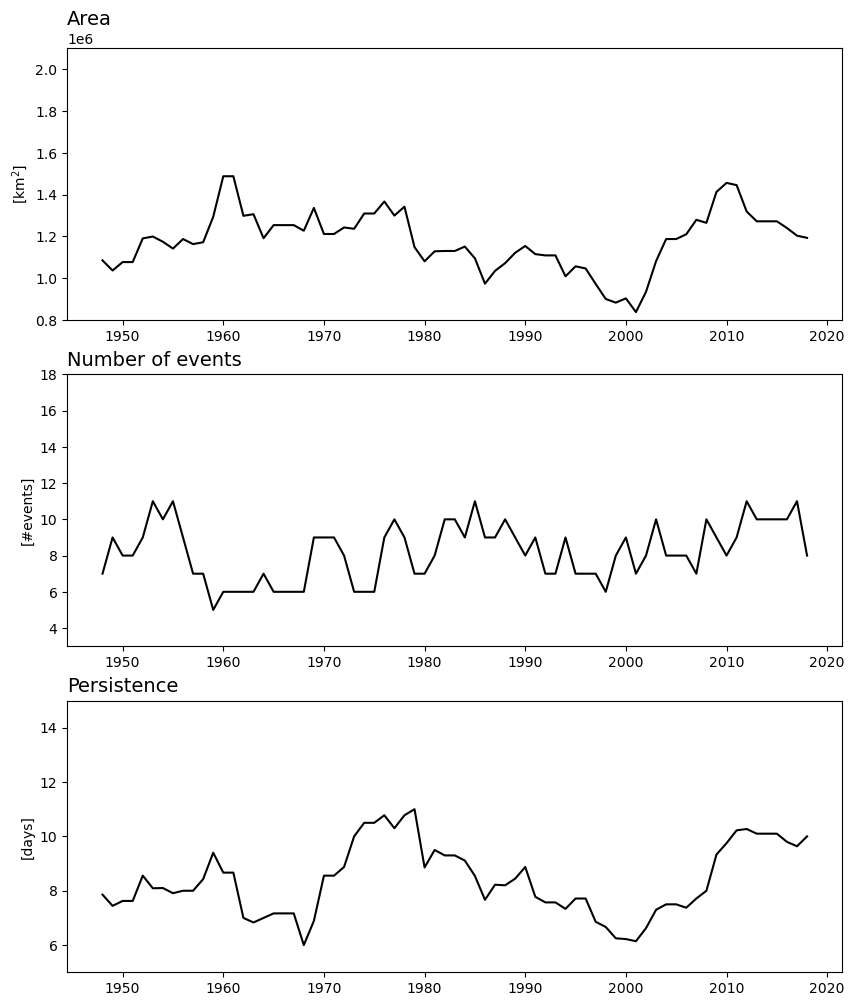

In [89]:
#WEST

y,area,area_err = feature_list(feature_dictionaries_west,'avg_area')
y,n_ev,n_ev_err = feature_list(feature_dictionaries_west,'number_of_events')
y,duration,duration_err = feature_list(feature_dictionaries_west,'duration')
# Fit linear regression model with errors

pend,p_value = fit_with_bootstrap(area,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(n_ev,y,2000)
print(pend,p_value)
pend,p_value = fit_with_bootstrap(duration,y,2000)
print(pend,p_value)
print(len(feature_dictionaries_west))

plt.rcParams['figure.figsize'] = [10,12]
fig, axes = plt.subplots(nrows=3,ncols=1)
axes.flatten()
axes[0].plot(y,area,color='black',label='area')
axes[0].set_title('Area',loc='left',fontsize=14)
axes[0].set_ylabel('[km$^2$]')
axes[0].set_ylim((0.8e6,2.1e6))
axes[1].plot(y,n_ev,color='black',label='number_of_events')
axes[1].set_title('Number of events',loc='left',fontsize=14)
axes[1].set_ylabel('[#events]')
axes[1].set_ylim((3,18))
axes[2].plot(y,duration,color='black',label='persistence')
axes[2].set_title('Persistence',loc='left',fontsize=14)
axes[2].set_ylabel('[days]')
axes[2].set_ylim((5,15))

plt.savefig('/Users/michelefilippucci/PLOTS/EGU/characteristics_from_west.png',dpi=300)

In [90]:
#COMPOSITES EAST WEST

In [91]:
labels_est = []
for event in feature_dictionaries_east:
    labels_est.append(event['label'])
labels_west = []
for event in feature_dictionaries_west:
    labels_west.append(event['label'])

In [85]:
print(labels_est)
print(labels_west)

[63, 232, 283, 288, 380, 460, 508, 519, 574, 756, 820, 931, 935, 988, 1051, 1053, 1113, 1177, 1186, 1414, 1460, 1519, 1530, 1757, 1770, 1993, 2000, 2067, 2123, 2187, 2238, 2288, 2296, 2348, 2464, 2466, 2468, 2475, 2593, 2605, 2764, 2771, 2839, 2845, 2949, 2952, 2957, 3004, 3011, 3066, 3130, 3196, 3204, 3209, 3318, 3375, 3440, 3486, 3493, 3593, 3605, 3649, 3658, 3709, 3726, 3777, 3782, 3783, 3838, 3912, 3916, 4018, 4029, 4084, 4278, 4330, 4478, 4492, 4553, 4609, 4653, 4663, 4718, 4767, 4771]
[235, 449, 578, 584, 631, 646, 696, 759, 762, 925, 987, 995, 1116, 1297, 1415, 1531, 1589, 1592, 1637, 1879, 1930, 1939, 1943, 1999, 2243, 2342, 2349, 2353, 2402, 2533, 2596, 2658, 2714, 2722, 2892, 2904, 2953, 3002, 3074, 3254, 3262, 3423, 3429, 3532, 3595, 3715, 3724, 3776, 3913, 3959, 3961, 4154, 4266, 4274, 4281, 4323, 4433, 4488, 4489, 4493, 4546, 4726, 4777, 4883]
